# Étape 2 — Partie Membre 3 : variables catégorielles et feature engineering

**Entrée** : `data_etape2b.csv` (sortie du membre 2) — 69 987 séjours, 56 colonnes.

**Partie 1 (ce notebook)**
- 3.0 Chargement
- 3.1 Suppression de `readmitted`
- 3.2 Exploration des variables catégorielles et lien avec la cible
- 3.3 Regroupement des codes `*_id`
- 3.4 Regroupement de `payer_code`
- 3.5 Regroupement des diagnostics ICD-9

**Partie 2**
- 3.6 `age` en variable ordinale
- 3.7 `A1Cresult` et `max_glu_serum` : deux indicateurs chacun
- 3.8 Les 23 médicaments
- 3.9 Feature engineering : `frequent_user`, `diabetes_complicated`, `n_changes`, `total_visits`
- 3.10 Encodage one-hot, suppression des identifiants, sauvegarde des fichiers finaux

**Sorties** : `data_etape2c_lisible.csv` (catégories en texte, pour interpréter) et `data_etape2c_encodee.csv` (tout numérique, pour modéliser).

---
### 3.0 Chargement

Lecture imposée par la note du membre 2 : `None` (examen non réalisé) doit rester une catégorie, et seules les cases vides deviennent des valeurs manquantes.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

df = pd.read_csv('data_etape2b.csv', keep_default_na=False, na_values=[''], low_memory=False)

print("Dimensions            :", df.shape)
print("'None' dans A1Cresult :", (df['A1Cresult'] == 'None').sum(), "(attendu : 57141)")
print("Valeurs manquantes    :")
print(df.isna().sum()[df.isna().sum() > 0])

Dimensions            : (69987, 56)
'None' dans A1Cresult : 57141 (attendu : 57141)
Valeurs manquantes    :
diag_1      10
diag_2     293
diag_3    1224
dtype: int64


---
### 3.1 Suppression de `readmitted`

La cible `target` a été créée à partir de `readmitted` à l'étape 1, et les deux colonnes sont toujours présentes. Contiennent-elles la même information ?

In [17]:
pd.crosstab(df['readmitted'], df['target'])

target,0,1
readmitted,,
<30,0,6285
>30,22226,0
NO,41476,0


In [18]:
df = df.drop(columns=['readmitted'])
print("Dimensions :", df.shape)

Dimensions : (69987, 55)


#### Décision : suppression de `readmitted`
La correspondance est parfaite : `<30` ↔ 1, `>30` et `NO` ↔ 0. Laisser `readmitted` dans les données reviendrait à **donner la réponse au modèle** (fuite de la cible) : il obtiendrait un score quasi parfait, sans aucune valeur réelle, puisque cette information n'existe pas au moment de la sortie du patient.

Les identifiants `encounter_id` et `patient_nbr` sont conservés pour l'instant (traçabilité), mais ils n'ont aucun sens médical : ils seront retirés du fichier de modélisation à la fin de cette étape.

---
### 3.2 Exploration des variables catégorielles et lien avec la cible

L'exploration de l'étape 1 a été faite sur les données brutes (101 766 séjours). Le nettoyage (un séjour par patient, suppression des décès) a changé la population : nous refaisons l'analyse sur les données nettoyées.

Deux outils :
- le **taux de réadmission par catégorie**, comparé au taux global ;
- le **V de Cramér**, qui mesure la force du lien entre une variable catégorielle et la cible, de 0 (aucun lien) à 1 (lien parfait). Il est calculé à partir du test du χ² : on compare, dans chaque catégorie, le nombre de réadmis observé au nombre attendu si la variable n'avait aucun effet. C'est l'équivalent, pour les variables catégorielles, de la corrélation utilisée pour les variables numériques.

Nous utilisons le V de Cramér plutôt que la p-value du χ² : avec 70 000 séjours, presque tous les tests sont « significatifs », même pour des écarts négligeables. Le V de Cramér mesure l'**ampleur** du lien.

In [19]:
taux_global = df['target'].mean() * 100
print(f"Taux global de réadmission <30j : {taux_global:.1f} %")

def taux_par_categorie(col):
    """Nombre de séjours et taux de réadmission (%) pour chaque catégorie de col."""
    t = df.groupby(col)['target'].agg(sejours='size', taux='mean')
    t['taux'] = (t['taux'] * 100).round(1)
    return t.sort_values('sejours', ascending=False)

def v_de_cramer(serie):
    """Force du lien entre une colonne et la cible : 0 = aucun lien, 1 = lien parfait."""
    observe = pd.crosstab(serie, df['target'])
    attendu = np.outer(observe.sum(axis=1), observe.sum(axis=0)) / len(df)
    chi2 = ((observe - attendu) ** 2 / attendu).values.sum()
    return np.sqrt(chi2 / len(df))   # cible binaire : min(lignes, colonnes) - 1 = 1

Taux global de réadmission <30j : 9.0 %


In [20]:
categorielles = ['age', 'gender', 'race',
                 'admission_type_id', 'admission_source_id', 'discharge_disposition_id',
                 'payer_code', 'medical_specialty',
                 'A1Cresult', 'max_glu_serum', 'insulin', 'change', 'diabetesMed']

resume = pd.DataFrame({
    'modalités': [df[c].nunique() for c in categorielles],
    'V de Cramér': [round(v_de_cramer(df[c]), 3) for c in categorielles],
}, index=categorielles)
resume.sort_values('V de Cramér', ascending=False)

,modalités,V de Cramér
discharge_disposition_id,20,0.137
age,10,0.052
payer_code,18,0.044
diabetesMed,2,0.028
medical_specialty,9,0.027
insulin,4,0.027
race,6,0.016
admission_source_id,15,0.015
change,2,0.015
admission_type_id,6,0.014


- `discharge_disposition_id` (destination de sortie) est de loin la variable catégorielle la plus liée à la réadmission (0,137), loin devant toutes les autres (0,052 au plus).
- Tous les liens restent faibles : comme pour les variables numériques (corrélation maximale de 0,14), aucune variable seule ne prédit bien la réadmission.
- `gender` n'a pratiquement aucun lien avec la cible (0,002).
- **Limite** : les catégories très rares gonflent artificiellement le V de Cramér (une catégorie de 2 séjours dont 1 réadmis pèse dans le calcul). C'est un argument de plus pour les regrouper (3.3).

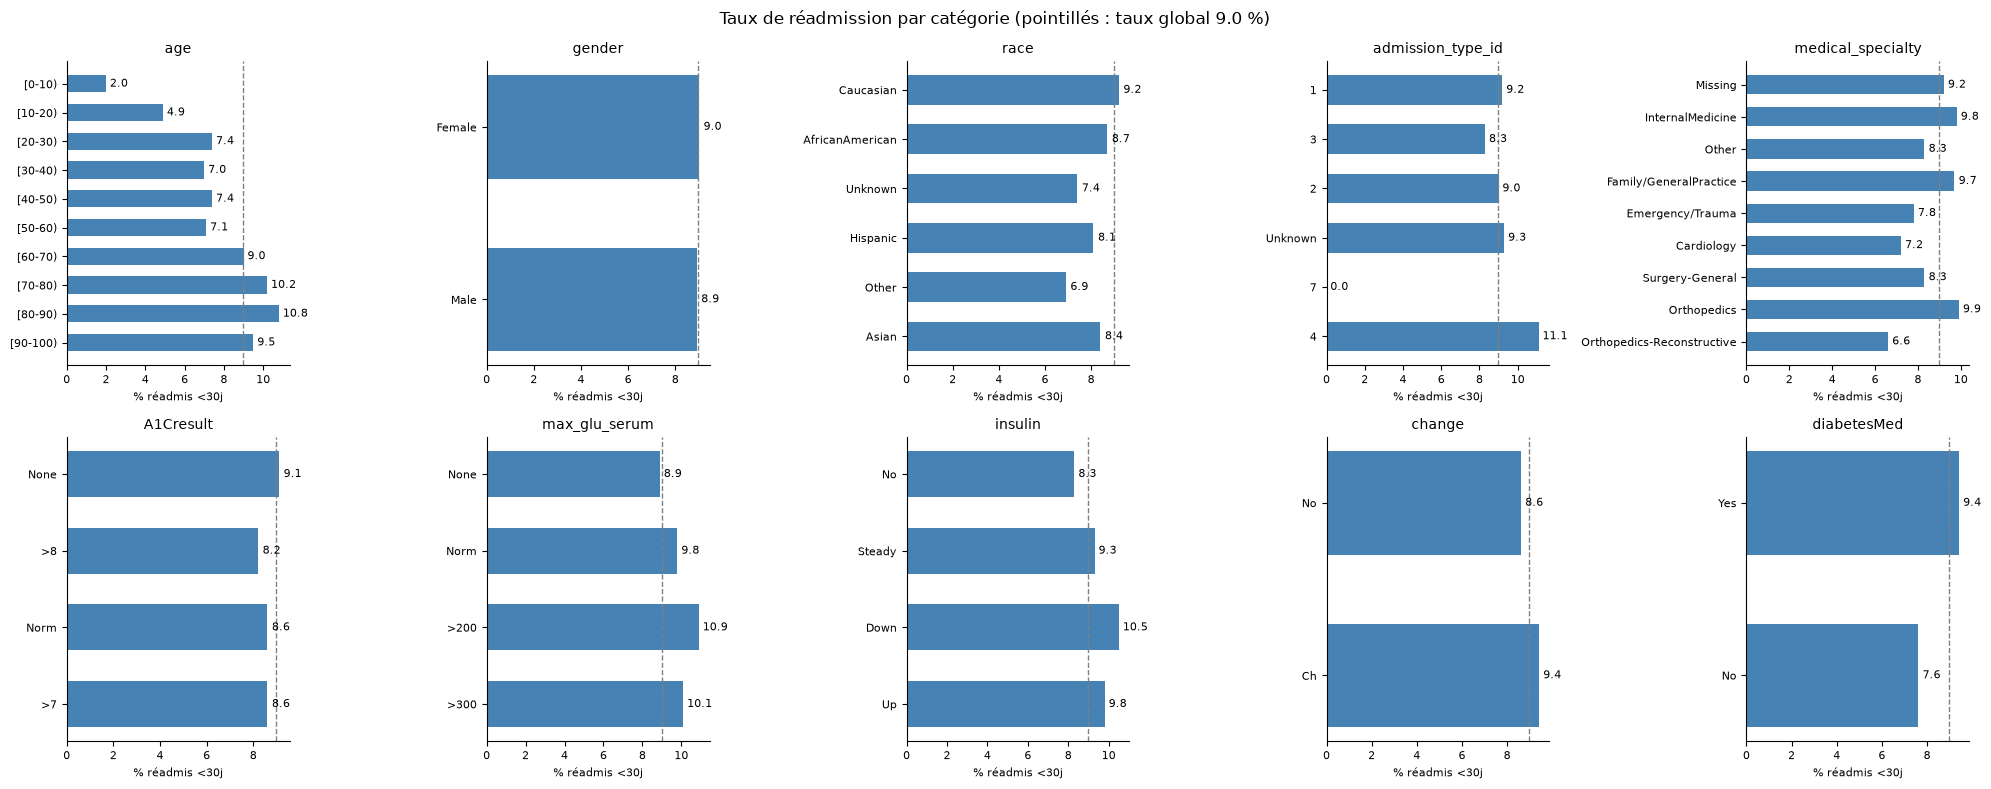

In [21]:
def tracer_taux(ax, col, ordre=None):
    """Barres horizontales : taux de réadmission par catégorie, pointillés = taux global."""
    t = taux_par_categorie(col)
    if ordre is not None:
        t = t.reindex(ordre)
    ax.barh(t.index.astype(str), t['taux'], color='steelblue', height=0.6)
    ax.axvline(taux_global, color='gray', linestyle='--', linewidth=1)
    for y, v in enumerate(t['taux']):
        ax.text(v + 0.2, y, f'{v:.1f}', va='center', fontsize=8)
    ax.invert_yaxis()
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('% réadmis <30j', fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)

a_tracer = ['age', 'gender', 'race', 'admission_type_id', 'medical_specialty',
            'A1Cresult', 'max_glu_serum', 'insulin', 'change', 'diabetesMed']

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.ravel(), a_tracer):
    tracer_taux(ax, col, ordre=sorted(df['age'].unique()) if col == 'age' else None)
fig.suptitle(f"Taux de réadmission par catégorie (pointillés : taux global {taux_global:.1f} %)")
plt.tight_layout()
plt.show()

**Lecture des graphiques**
- **Âge** : contrairement à la conclusion de l'étape 1 (calculée sur les données brutes), l'âge a un effet net après nettoyage. Le taux passe d'environ 7 % entre 20 et 60 ans à 10,2 % (70–80 ans) et 10,8 % (80–90 ans). Les moins de 20 ans sont très peu réadmis (2 à 5 %), mais ne représentent que 1 % des séjours.
- **Traitement du diabète** : les patients traités (`diabetesMed = Yes` : 9,4 % contre 7,6 %), dont le traitement est modifié (`change = Ch` : 9,4 % contre 8,6 %) ou dont l'insuline est ajustée (`Down` : 10,5 %, `Up` : 9,8 %, contre 8,3 % sans insuline) sont un peu plus réadmis. Ce sont probablement des diabètes plus difficiles à équilibrer.
- **Examens** : les écarts sont faibles. Les séjours sans HbA1c (`None`) ont un taux à peine supérieur (9,1 % contre 8,2 à 8,6 %). Une glycémie très élevée (`max_glu_serum > 200` : 10,9 %) est associée à un taux un peu plus haut, mais ne concerne que 1 % des séjours.
- **Spécialité** : de 6,6 % (orthopédie reconstructive) à 9,9 % (orthopédie), sans tendance nette.
- **Sexe** et **origine** : effet quasi nul ; les écarts de `race` concernent surtout de petites catégories.

In [22]:
# Modalités rares dans les colonnes à codes
for col in ['admission_type_id', 'admission_source_id', 'discharge_disposition_id', 'payer_code']:
    t = taux_par_categorie(col)
    print(f"{col:26s} : {len(t):2d} modalités, dont {(t['sejours'] < 100).sum():2d} avec moins de 100 séjours")

admission_type_id          :  6 modalités, dont  2 avec moins de 100 séjours
admission_source_id        : 15 modalités, dont  7 avec moins de 100 séjours
discharge_disposition_id   : 20 modalités, dont 10 avec moins de 100 séjours
payer_code                 : 18 modalités, dont  4 avec moins de 100 séjours


In [23]:
taux_par_categorie('discharge_disposition_id').T

discharge_disposition_id,1,3,6,Unknown,2,22,5,4,7,23,28,8,15,24,9,17,10,27,16,12
sejours,44320.0,8790.0,8291.0,3252.0,1541.0,1410.0,913.0,542.0,409.0,260.0,90.0,73.0,40.0,25.0,9.0,8.0,6.0,3.0,3.0,2.0
taux,6.9,13.4,9.5,9.2,13.8,26.4,20.6,10.3,9.5,3.1,35.6,9.6,45.0,4.0,22.2,0.0,0.0,0.0,0.0,50.0


#### Conclusion — exploration des catégorielles
- Les colonnes à codes contiennent beaucoup de **modalités rares** : 10 des 20 codes de sortie et 7 des 15 codes de source d'admission ont moins de 100 séjours.
- Sur de si petits effectifs, les taux ne sont **pas fiables** : le code de sortie 12 affiche 50 % de réadmission… sur 2 séjours, et les codes 10, 16, 17 et 27 affichent 0 % sur 3 à 8 séjours. Un modèle pourrait apprendre ces accidents par cœur (**surapprentissage**).
- À l'inverse, certains codes peu fréquents portent un **vrai signal** : 22 (centre de rééducation : 26,4 % sur 1 410 séjours) et 5 (autre établissement de soins : 20,6 % sur 913 séjours). Le regroupement doit donc se faire **par signification**, et pas seulement par fréquence.

---
### 3.3 Regroupement des codes `*_id`

Le membre 1 a déjà regroupé les codes qui signifient « information indisponible » (NULL, Not Mapped, Not Available…) en `Unknown` : c'était un problème de **valeurs manquantes**. Il reste un problème d'**encodage** : trop de codes réels, dont beaucoup sont rares.

**Pourquoi regrouper ?**
1. Les taux calculés sur quelques séjours ne sont que du bruit (voir 3.2).
2. L'encodage one-hot crée une colonne par modalité : 41 colonnes pour ces trois variables, presque toutes vides. Cela bruite les distances de K-Means et rend instables les coefficients de la régression logistique.
3. Une modalité de 2 séjours peut se retrouver uniquement dans l'ensemble de test : le modèle ne l'aura jamais vue.
4. Plusieurs codes ont le même sens médical (par exemple 3, 4, 23 et 24 désignent tous un établissement de soins).

**Groupes retenus** (libellés tirés de `IDS_mapping.csv`) :

| Variable | Groupe | Codes | Signification |
|---|---|---|---|
| `discharge_disposition_id` | Home | 1 | Retour à domicile |
| | Home with care | 6, 8, 12, 16, 17 | Domicile avec soins à domicile ou suivi ambulatoire |
| | Care facility | 3, 4, 15, 23, 24 | Maison de soins (SNF, ICF), soins de suite, long séjour |
| | Other hospital / rehab | 2, 5, 9, 10, 22, 27, 28, 29, 30 | Autre hôpital, rééducation, psychiatrie, autre établissement |
| | Left AMA | 7 | Sortie contre avis médical |
| | Unknown | Unknown | Information indisponible |
| `admission_source_id` | Emergency room | 7 | Arrivée par les urgences |
| | Referral | 1, 2, 3 | Adressé par un médecin, une clinique ou un HMO |
| | Transfer | 4, 5, 6, 10, 18, 22, 25, 26 | Transfert depuis un autre établissement |
| | Other / Unknown | 8, 11, 13, 14, 23, 24, Unknown | Police/justice, codes de naissance, information indisponible |
| `admission_type_id` | Emergency | 1, 7 | Urgence (dont centre de traumatologie) |
| | Urgent | 2 | Urgent |
| | Elective | 3 | Programmé |
| | Other / Unknown | 4, Unknown | Nouveau-né, information indisponible |

- Les codes de naissance (nouveau-né, accouchement) sont incohérents avec une population de patients diabétiques et très rares (13 séjours au total) : ce sont probablement des erreurs de codage. Ils rejoignent `Other / Unknown` plutôt que de former leur propre modalité.
- Quelques codes du dictionnaire sont absents des données nettoyées (par exemple 29 et 30) : ils sont tout de même listés pour que le regroupement reste complet.

In [24]:
groupes_sortie = {
    '1': 'Home',
    '6': 'Home with care', '8': 'Home with care',
    '12': 'Home with care', '16': 'Home with care', '17': 'Home with care',
    '3': 'Care facility', '4': 'Care facility', '15': 'Care facility',
    '23': 'Care facility', '24': 'Care facility',
    '2': 'Other hospital / rehab', '5': 'Other hospital / rehab', '9': 'Other hospital / rehab',
    '10': 'Other hospital / rehab', '22': 'Other hospital / rehab', '27': 'Other hospital / rehab',
    '28': 'Other hospital / rehab', '29': 'Other hospital / rehab', '30': 'Other hospital / rehab',
    '7': 'Left AMA',
    'Unknown': 'Unknown',
}
groupes_source = {
    '7': 'Emergency room',
    '1': 'Referral', '2': 'Referral', '3': 'Referral',
    '4': 'Transfer', '5': 'Transfer', '6': 'Transfer', '10': 'Transfer',
    '18': 'Transfer', '22': 'Transfer', '25': 'Transfer', '26': 'Transfer',
    '8': 'Other / Unknown', '11': 'Other / Unknown', '13': 'Other / Unknown',
    '14': 'Other / Unknown', '23': 'Other / Unknown', '24': 'Other / Unknown',
    'Unknown': 'Other / Unknown',
}
groupes_type = {
    '1': 'Emergency', '7': 'Emergency',
    '2': 'Urgent',
    '3': 'Elective',
    '4': 'Other / Unknown', 'Unknown': 'Other / Unknown',
}
regroupements = {
    'discharge_disposition_id': groupes_sortie,
    'admission_source_id': groupes_source,
    'admission_type_id': groupes_type,
}

In [25]:
avant = df[list(regroupements)].copy()   # copie pour comparer avant / après

for col, groupes in regroupements.items():
    df[col] = df[col].map(groupes)
    assert df[col].notna().all(), f"un code de {col} n'a pas de groupe"

pd.DataFrame({
    'modalités avant': [avant[c].nunique() for c in regroupements],
    'modalités après': [df[c].nunique() for c in regroupements],
    'V de Cramér avant': [round(v_de_cramer(avant[c]), 3) for c in regroupements],
    'V de Cramér après': [round(v_de_cramer(df[c]), 3) for c in regroupements],
}, index=list(regroupements))

,modalités avant,modalités après,V de Cramér avant,V de Cramér après
discharge_disposition_id,20,6,0.137,0.122
admission_source_id,15,4,0.015,0.011
admission_type_id,6,4,0.014,0.013


In [26]:
for col in regroupements:
    print(taux_par_categorie(col), '\n')

                          sejours  taux
discharge_disposition_id               
Home                        44320   6.9
Care facility                9657  13.1
Home with care               8377   9.5
Other hospital / rehab       3972  20.3
Unknown                      3252   9.2
Left AMA                      409   9.5 

                     sejours  taux
admission_source_id               
Emergency room         37271   9.3
Referral               22792   8.7
Other / Unknown         5084   8.9
Transfer                4840   8.4 

                   sejours  taux
admission_type_id               
Emergency            35496   9.2
Elective             13786   8.3
Urgent               12803   9.0
Other / Unknown       7902   9.3 



#### Décision : regroupement par signification
- **Sortie** : 20 → 6 modalités. Les groupes ont des taux bien distincts : 6,9 % (domicile), 9,5 % (domicile avec soins), 13,1 % (établissement de soins), 20,3 % (autre hôpital / rééducation). Plus le patient a besoin de soins à sa sortie, plus il est réadmis.
- Le V de Cramér de la sortie baisse un peu (0,137 → 0,122). Une partie de cette baisse vient de la disparition du bruit des petites modalités. L'autre vient de la fusion de codes aux taux différents : par exemple la psychiatrie (code 28 : 35,6 % sur 90 séjours) rejoint « Other hospital / rehab ». C'est le prix d'une variable stable et interprétable.
- **Source et type d'admission** : 15 → 4 et 6 → 4 modalités. Tous les groupes ont un taux proche du taux global (8,3 à 9,3 %) : ces deux variables sont très peu liées à la réadmission (V ≈ 0,01). Le regroupement ne fait donc rien perdre.

---
### 3.4 Regroupement de `payer_code`

`payer_code` (organisme qui paie le séjour) compte 18 modalités, dont 4 de moins de 100 séjours (`FR` : 1 seul séjour). Le dataset ne fournit **pas la signification des codes** : contrairement aux codes `*_id`, on ne peut pas regrouper par sens. Nous regroupons donc par **fréquence** : les codes représentant moins de 1 % des séjours rejoignent `Other`. `Missing` (catégorie créée par le membre 1) est conservé à part.

In [27]:
freq = df['payer_code'].value_counts(normalize=True)
rares = freq[freq < 0.01].index.drop('Missing', errors='ignore')
print("Codes regroupés dans 'Other' :", list(rares))
print("Séjours concernés            :", df['payer_code'].isin(rares).sum())

df['payer_code'] = df['payer_code'].replace(list(rares), 'Other')
taux_par_categorie('payer_code').T

Codes regroupés dans 'Other' : ['OG', 'PO', 'DM', 'WC', 'CH', 'OT', 'SI', 'MP', 'FR']
Séjours concernés            : 1838


payer_code,Missing,MC,HM,BC,SP,MD,CP,UN,Other,CM
sejours,30415.0,19795.0,3984.0,3397.0,3303.0,2167.0,1937.0,1855.0,1838.0,1296.0
taux,9.9,9.4,7.0,6.0,8.0,7.9,6.5,7.6,7.1,8.1


#### Décision : codes de moins de 1 % regroupés dans `Other`
- 18 → 10 modalités : 9 codes rares (1 838 séjours, 2,6 %) regroupés.
- Seuil de 1 % : en dessous, une modalité compte moins de 700 séjours, soit environ 60 réadmis attendus. C'est trop peu pour estimer un taux stable.
- `Missing` reste la modalité la plus réadmise (9,9 %) : l'absence d'information sur le payeur est elle-même informative, ce qui justifie de l'avoir gardée séparée.

---
### 3.5 Regroupement des diagnostics `diag_1`, `diag_2`, `diag_3`

Ce sont les seules colonnes qui contiennent encore des valeurs manquantes. Avant de les regrouper, il faut comprendre **pourquoi** elles sont vides.

In [28]:
for col in ['diag_1', 'diag_2', 'diag_3']:
    manquant = df[col].isna()
    print(f"{col} : {manquant.sum():5d} manquants | "
          f"number_diagnoses moyen si manquant : {df.loc[manquant, 'number_diagnoses'].mean():.1f} | "
          f"si renseigné : {df.loc[~manquant, 'number_diagnoses'].mean():.1f}")

print()
print("Séjours sans diag_3 ayant au plus 2 diagnostics :",
      f"{(df.loc[df['diag_3'].isna(), 'number_diagnoses'] <= 2).mean():.1%}")

diag_1 :    10 manquants | number_diagnoses moyen si manquant : 6.6 | si renseigné : 7.2
diag_2 :   293 manquants | number_diagnoses moyen si manquant : 2.4 | si renseigné : 7.2
diag_3 :  1224 manquants | number_diagnoses moyen si manquant : 2.2 | si renseigné : 7.3

Séjours sans diag_3 ayant au plus 2 diagnostics : 87.7%


#### Les valeurs manquantes ne sont pas toutes de vrais manquants
- **`diag_2` et `diag_3`** : les séjours concernés ont en moyenne 2,2 à 2,4 diagnostics, contre 7,2 pour les autres, et 87,7 % des séjours sans `diag_3` ont au plus 2 diagnostics. La case est vide parce qu'**il n'y a pas de 2e ou de 3e diagnostic** : c'est une information, pas un oubli. → catégorie **`Absent`**.
- **`diag_1`** (diagnostic principal) : 10 séjours seulement, avec un nombre de diagnostics normal (6,6). Ce sont de vrais manquants, mais trop peu nombreux pour former une catégorie (même problème que les codes rares en 3.3). → rangés dans **`Other`**.

In [29]:
codes = pd.concat([df['diag_1'], df['diag_2'], df['diag_3']]).dropna()
print("Codes distincts           :", codes.nunique())
print("Codes en V (facteurs)     :", f"{codes.str.startswith('V').mean():.1%}")
print("Codes en E (causes ext.)  :", f"{codes.str.startswith('E').mean():.1%}")
print("Exemples                  :", codes.sample(8, random_state=0).tolist())

Codes distincts           : 894
Codes en V (facteurs)     : 2.3%
Codes en E (causes ext.)  : 0.7%
Exemples                  : ['401', '38', '998', '682', '38', '162', '41', '535']


#### Méthode : regroupement en familles de maladies
894 codes ICD-9 distincts sont inutilisables tels quels : l'encodage créerait une colonne par code. Nous utilisons le regroupement de l'étude d'origine (Strack et al., 2014), qui classe les codes selon le système du corps atteint :

| Famille | Codes ICD-9 | Exemples |
|---|---|---|
| Circulatory | 390–459, 785 | Insuffisance cardiaque (428), infarctus (410) |
| Respiratory | 460–519, 786 | Pneumonie (486), bronchite chronique (491) |
| Digestive | 520–579, 787 | Maladies de l'estomac, de l'intestin, du foie |
| Diabetes | 250.xx | Diabète et ses complications |
| Injury | 800–999 | Fractures, complications de soins |
| Musculoskeletal | 710–739 | Arthrose (715) |
| Genitourinary | 580–629, 788 | Insuffisance rénale, infections urinaires |
| Neoplasms | 140–239 | Tumeurs |
| Other | autres codes, codes V et E | Peau, infections, troubles mentaux… |

Les codes en **V** (facteurs influençant l'état de santé) et en **E** (causes externes de blessure) ne sont pas des maladies : ils rejoignent `Other`.

Nous préférons ce regroupement à un regroupement par fréquence : il a un **sens médical**, il est **reconnu** (étude d'origine du dataset) et il reste **interprétable** pour la segmentation et la présentation.

In [30]:
def groupe_icd9(code):
    """Famille de maladies d'un code ICD-9 (regroupement de Strack et al., 2014)."""
    if pd.isna(code):
        return 'Absent'
    if code.startswith(('V', 'E')):
        return 'Other'                      # facteurs de santé (V) et causes externes (E)
    x = float(code)
    if 390 <= x < 460 or int(x) == 785:
        return 'Circulatory'
    if 460 <= x < 520 or int(x) == 786:
        return 'Respiratory'
    if 520 <= x < 580 or int(x) == 787:
        return 'Digestive'
    if int(x) == 250:
        return 'Diabetes'
    if 800 <= x < 1000:
        return 'Injury'
    if 710 <= x < 740:
        return 'Musculoskeletal'
    if 580 <= x < 630 or int(x) == 788:
        return 'Genitourinary'
    if 140 <= x < 240:
        return 'Neoplasms'
    return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df[col + '_groupe'] = df[col].apply(groupe_icd9)

# diag_1 : les 10 vrais manquants rejoignent 'Other' (trop peu pour une catégorie)
df['diag_1_groupe'] = df['diag_1_groupe'].replace('Absent', 'Other')

# Répartition (%) des familles pour chaque diagnostic
pd.DataFrame({c: df[c + '_groupe'].value_counts(normalize=True).mul(100).round(1)
              for c in ['diag_1', 'diag_2', 'diag_3']}).fillna(0).sort_values('diag_1', ascending=False)

,diag_1,diag_2,diag_3
Circulatory,30.6,31.6,29.8
Other,17.3,25.8,28.6
Respiratory,13.6,9.9,6.6
Digestive,9.3,4.1,3.9
Diabetes,8.2,13.9,17.9
Injury,6.7,2.6,2.0
Musculoskeletal,5.8,1.9,2.0
Genitourinary,4.9,7.6,5.8
Neoplasms,3.6,2.3,1.6
Absent,0.0,0.4,1.7


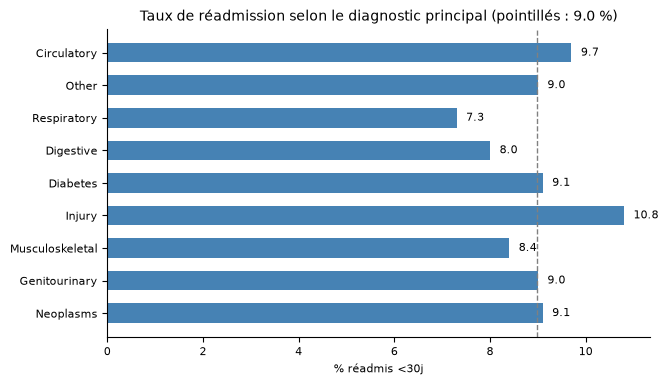

V de Cramér diag_1_groupe : 0.032
V de Cramér diag_2_groupe : 0.027
V de Cramér diag_3_groupe : 0.030


In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
tracer_taux(ax, 'diag_1_groupe')
ax.set_title(f"Taux de réadmission selon le diagnostic principal (pointillés : {taux_global:.1f} %)", fontsize=10)
plt.show()

for col in ['diag_1_groupe', 'diag_2_groupe', 'diag_3_groupe']:
    print(f"V de Cramér {col} : {v_de_cramer(df[col]):.3f}")

#### Décision : familles ICD-9
- 894 codes → 9 familles pour `diag_1`, et 10 pour `diag_2` et `diag_3` (avec `Absent`).
- Les maladies **circulatoires** dominent (31 % des diagnostics principaux). Le **diabète** n'est le diagnostic principal que dans 8,2 % des séjours, mais il est plus fréquent en diagnostic secondaire (13,9 % et 17,9 %) : il accompagne le motif d'hospitalisation plus qu'il ne le cause, comme observé à l'étape 1.
- Les **traumatismes** (`Injury` : 10,8 %) et les maladies **circulatoires** (9,7 %) sont les plus réadmis, les maladies **respiratoires** le moins (7,3 %).
- **Limite** : `Other` reste large (17 à 29 % selon le diagnostic) car il réunit des chapitres variés (peau, infections, troubles mentaux, symptômes…). Le découper recréerait des modalités rares.
- Les codes bruts sont supprimés des données : leurs familles les remplacent. Une copie est gardée dans `diag_brut` pour le feature engineering (3.9).

In [32]:
# Copie des codes bruts : elle servira au feature engineering (3.9)
diag_brut = df[['diag_1', 'diag_2', 'diag_3']].copy()

df = df.drop(columns=['diag_1', 'diag_2', 'diag_3'])
print("Dimensions                   :", df.shape)
print("Valeurs manquantes restantes :", df.isna().sum().sum())

Dimensions                   : (69987, 55)
Valeurs manquantes restantes : 0


---
## 📌 Récapitulatif — Partie 1

Lien de chaque variable catégorielle avec la cible, après regroupement :

In [33]:
categorielles_finales = ['age', 'gender', 'race',
                         'admission_type_id', 'admission_source_id', 'discharge_disposition_id',
                         'payer_code', 'medical_specialty',
                         'diag_1_groupe', 'diag_2_groupe', 'diag_3_groupe',
                         'A1Cresult', 'max_glu_serum', 'insulin', 'change', 'diabetesMed']
pd.DataFrame({
    'modalités': [df[c].nunique() for c in categorielles_finales],
    'V de Cramér': [round(v_de_cramer(df[c]), 3) for c in categorielles_finales],
}, index=categorielles_finales).sort_values('V de Cramér', ascending=False)

,modalités,V de Cramér
discharge_disposition_id,6,0.122
age,10,0.052
payer_code,10,0.043
diag_1_groupe,9,0.032
diag_3_groupe,10,0.030
diabetesMed,2,0.028
diag_2_groupe,10,0.027
medical_specialty,9,0.027
insulin,4,0.027
race,6,0.016


La **destination de sortie** reste, de loin, la variable catégorielle la plus liée à la réadmission, suivie de l'**âge**, du **payeur** et du **diagnostic principal**. Tous les liens sont faibles : la classification devra combiner de nombreuses variables.

| Problème | Variable(s) | Traitement | Justification |
|---|---|---|---|
| Fuite de la cible | `readmitted` | Suppression | Contient exactement la même information que `target` |
| Codes réels trop nombreux et rares | 3 colonnes `*_id` | Regroupement par signification (20 → 6, 15 → 4, 6 → 4) | Taux instables, colonnes vides après encodage, codes de même sens |
| Codes trop nombreux, sans dictionnaire | `payer_code` | Codes < 1 % des séjours → `Other` (18 → 10) | Signification inconnue : regroupement par fréquence |
| 894 codes de diagnostic | `diag_1/2/3` | Familles ICD-9 (Strack et al., 2014) | Sens médical, interprétable, reconnu |
| Cases vides structurelles | `diag_2`, `diag_3` | Catégorie `Absent` | Pas de 2e ou 3e diagnostic : c'est une information |
| Vrais manquants (10 séjours) | `diag_1` | Rangés dans `Other` | Trop peu pour former une catégorie |

**État à la fin de la partie 1** : 69 987 séjours, 55 colonnes, **aucune valeur manquante**.

---
# Partie 2

### 3.6 `age` : variable ordinale

`age` est donné en tranches de 10 ans (`[0-10)`, `[10-20)`, …). Ces tranches ont un **ordre naturel** : 75 ans, c'est plus que 45 ans.
- Un encodage **one-hot** (une colonne par tranche) ferait perdre cet ordre et créerait 10 colonnes.
- Un encodage **ordinal** conserve l'ordre en une seule colonne.

Nous remplaçons chaque tranche par **son milieu** (5, 15, …, 95). C'est un encodage ordinal (l'ordre est respecté), mais exprimé en années : « 75 » se lit directement « environ 75 ans », alors qu'un rang de 0 à 9 demanderait une table de correspondance. Après mise à l'échelle (StandardScaler), les deux codages donnent exactement le même résultat.

In [34]:
age_milieu = {f'[{10 * i}-{10 * (i + 1)})': 10 * i + 5 for i in range(10)}
df['age'] = df['age'].map(age_milieu)
assert df['age'].notna().all(), "une tranche d'âge n'a pas été convertie"

taux_par_categorie('age').sort_index().T

age,5,15,25,35,45,55,65,75,85,95
sejours,153.0,534.0,1121.0,2692.0,6828.0,12351.0,15688.0,17749.0,11110.0,1761.0
taux,2.0,4.9,7.4,7.0,7.4,7.1,9.0,10.2,10.8,9.5


#### Décision : âge ordinal (milieu de la tranche)
- La relation avec la cible est globalement **croissante** : environ 7 % de réadmission entre 20 et 60 ans, 10,2 % à 75 ans, 10,8 % à 85 ans. Un codage ordinal permet aux modèles de capter cette tendance avec une seule variable.
- **Limite** : la relation n'est pas parfaitement linéaire (léger recul à 95 ans, taux très bas avant 20 ans). Les arbres de décision s'y adaptent seuls ; pour la régression logistique, c'est une approximation acceptable, car les moins de 20 ans ne représentent que 1 % des séjours.

---
### 3.7 `A1Cresult` et `max_glu_serum` : deux indicateurs chacun

Ces deux examens ont 4 valeurs : `None` (examen non réalisé), une valeur normale, et deux niveaux élevés. Ils ne sont **pas ordinaux** : `None` n'est pas un résultat, il ne se place pas sur l'échelle Normal < >7 < >8. Ils mélangent en fait deux informations :
1. **l'examen a-t-il été fait ?** (une décision du médecin, au cœur de l'étude d'origine) ;
2. **si oui, le résultat est-il anormal ?**

Nous séparons ces deux informations en deux indicateurs 0/1 :

| Valeur d'origine | `*_tested` | `*_high` | Lecture |
|---|---|---|---|
| `None` | 0 | 0 | Examen non réalisé |
| `Norm` | 1 | 0 | Examen fait, résultat normal |
| `>7`, `>8` (HbA1c) / `>200`, `>300` (glycémie) | 1 | 1 | Examen fait, résultat élevé |

Chaque valeur d'origine correspond à une combinaison unique : aucune information n'est perdue, sauf la distinction entre les deux niveaux élevés (justifiée ci-dessous).

In [35]:
df['A1C_tested'] = (df['A1Cresult'] != 'None').astype(int)
df['A1C_high']   = df['A1Cresult'].isin(['>7', '>8']).astype(int)
df['glu_tested'] = (df['max_glu_serum'] != 'None').astype(int)
df['glu_high']   = df['max_glu_serum'].isin(['>200', '>300']).astype(int)

# Vérification : chaque valeur d'origine correspond à une seule combinaison
print(pd.crosstab(df['A1Cresult'], [df['A1C_tested'], df['A1C_high']]), '\n')
print(pd.crosstab(df['max_glu_serum'], [df['glu_tested'], df['glu_high']]))

A1C_tested      0     1      
A1C_high        0     0     1
A1Cresult                    
>7              0     0  2866
>8              0     0  6239
None        57141     0     0
Norm            0  3741     0 

glu_tested         0     1     
glu_high           0     0    1
max_glu_serum                  
>200               0     0  936
>300               0     0  712
None           66638     0    0
Norm               0  1701    0


In [36]:
# Taux de réadmission des deux niveaux élevés : faut-il les distinguer ?
for col in ['A1Cresult', 'max_glu_serum']:
    print(taux_par_categorie(col).T, '\n')

A1Cresult     None      >8    Norm      >7
sejours    57141.0  6239.0  3741.0  2866.0
taux           9.1     8.2     8.6     8.6 

max_glu_serum     None    Norm   >200   >300
sejours        66638.0  1701.0  936.0  712.0
taux               8.9     9.8   10.9   10.1 



In [37]:
df = df.drop(columns=['A1Cresult', 'max_glu_serum'])
for col in ['A1C_tested', 'A1C_high', 'glu_tested', 'glu_high']:
    print(f"{col:11s} : {df[col].mean():6.1%} des séjours | V de Cramér : {v_de_cramer(df[col]):.3f}")

A1C_tested  :  18.4% des séjours | V de Cramér : 0.010
A1C_high    :  13.0% des séjours | V de Cramér : 0.009
glu_tested  :   4.8% des séjours | V de Cramér : 0.009
glu_high    :   2.4% des séjours | V de Cramér : 0.009


#### Décision : deux indicateurs par examen
- **Pas de perte d'information utile** : les deux niveaux élevés ont des taux de réadmission très proches (HbA1c `>7` : 8,6 % contre `>8` : 8,2 % ; glycémie `>200` : 10,9 % contre `>300` : 10,1 %). Les fusionner simplifie sans rien perdre.
- **Plus lisible** : « examen fait » et « résultat élevé » sont deux questions différentes, que l'on peut interpréter séparément dans les clusters et dans l'importance des variables.
- **Mieux adapté aux modèles** : deux colonnes 0/1 au lieu de 4 colonnes one-hot par examen, et pas d'ordre artificiel imposé à `None`.
- **Limite** : ces examens sont peu liés à la réadmission (V de Cramér ≤ 0,01). Ils sont conservés pour leur intérêt médical : la mesure de l'HbA1c est la question centrale de l'étude d'origine.

---
### 3.8 Les 23 médicaments

Chaque colonne de médicament prend 4 valeurs : `No` (non prescrit), `Steady` (dose stable), `Up` (dose augmentée), `Down` (dose diminuée). Deux problèmes :
- certains médicaments ne sont **jamais ou presque jamais** prescrits ;
- les doses modifiées (`Up` / `Down`) concernent souvent très peu de séjours.

In [38]:
meds = list(df.loc[:, 'metformin':'metformin-pioglitazone'].columns)

usage = pd.DataFrame({
    'séjours avec prescription': (df[meds] != 'No').sum(),
    '% des séjours': ((df[meds] != 'No').mean() * 100).round(2),
}).sort_values('séjours avec prescription', ascending=False)

constants = [m for m in meds if df[m].nunique() == 1]
print("Médicaments constants (jamais prescrits) :", constants)
usage

Médicaments constants (jamais prescrits) : ['examide', 'citoglipton', 'glimepiride-pioglitazone']


,séjours avec prescription,% des séjours
insulin,35722,51.04
metformin,14904,21.30
glipizide,9009,12.87
glyburide,7776,11.11
pioglitazone,5265,7.52
rosiglitazone,4660,6.66
glimepiride,3698,5.28
repaglinide,917,1.31
glyburide-metformin,496,0.71
nateglinide,491,0.70


In [39]:
# Garder les médicaments prescrits dans au moins 1 % des séjours (même seuil que payer_code)
garder = usage.index[usage['% des séjours'] >= 1].tolist()
a_supprimer = [m for m in meds if m not in garder]
print("Conservés  :", garder)
print("Supprimés  :", len(a_supprimer), "médicaments")
print("Séjours qui reçoivent au moins un médicament supprimé :",
      (df[a_supprimer] != 'No').any(axis=1).sum())

Conservés  : ['insulin', 'metformin', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'glimepiride', 'repaglinide']
Supprimés  : 15 médicaments
Séjours qui reçoivent au moins un médicament supprimé : 1327


In [40]:
# Nombre de séjours et taux de réadmission pour chaque niveau de dose
niveaux = ['No', 'Steady', 'Up', 'Down']
pd.DataFrame({
    m: [f"{(df[m] == v).sum():>6} | {df.loc[df[m] == v, 'target'].mean() * 100:4.1f} %" for v in niveaux]
    for m in garder
}, index=niveaux).T

,No,Steady,Up,Down
insulin,34265 | 8.3 %,21621 | 9.3 %,6777 | 9.8 %,7324 | 10.5 %
metformin,55083 | 9.2 %,13635 | 8.3 %,834 | 7.0 %,435 | 10.1 %
glipizide,60978 | 8.9 %,8065 | 9.5 %,573 | 11.0 %,371 | 12.9 %
glyburide,62211 | 8.9 %,6745 | 9.3 %,613 | 9.6 %,418 | 9.6 %
pioglitazone,64722 | 9.0 %,5006 | 8.6 %,178 | 11.8 %,81 | 11.1 %
rosiglitazone,65327 | 9.0 %,4454 | 8.8 %,132 | 9.8 %,74 | 5.4 %
glimepiride,66289 | 9.0 %,3332 | 8.5 %,230 | 10.0 %,136 | 13.2 %
repaglinide,69070 | 8.9 %,818 | 12.0 %,71 | 21.1 %,28 | 3.6 %


#### Lecture
- **`insulin`** : chaque niveau compte au moins 6 777 séjours, et les taux suivent une logique claire : 8,3 % sans insuline, 9,3 % à dose stable, 9,8 à 10,5 % quand la dose est modifiée. Ces 4 niveaux sont fiables et informatifs.
- **Les 7 autres** : `Up` et `Down` concernent de 28 à 834 séjours, avec des taux instables (`repaglinide` : 21,1 % pour `Up` sur 71 séjours, mais 3,6 % pour `Down` sur 28 séjours). Ces écarts relèvent du hasard.

In [41]:
# Copie des 23 colonnes d'origine : elle servira au feature engineering
# (compter les médicaments prescrits ou modifiés, y compris les médicaments supprimés)
meds_brut = df[meds].copy()

df = df.drop(columns=a_supprimer)

# 7 médicaments : prescrit (1) ou non (0) ; insulin garde ses 4 niveaux (encodée en one-hot plus tard)
for m in garder:
    if m != 'insulin':
        df[m] = (df[m] != 'No').astype(int)

# change et diabetesMed : variables oui / non
df['change'] = (df['change'] == 'Ch').astype(int)
df['diabetesMed'] = (df['diabetesMed'] == 'Yes').astype(int)

print("Dimensions :", df.shape)
df[garder + ['change', 'diabetesMed']].head()

Dimensions : (69987, 42)


,insulin,metformin,glipizide,glyburide,pioglitazone,rosiglitazone,glimepiride,repaglinide,change,diabetesMed
0,Steady,0,1,0,0,0,0,0,1,1
1,Steady,0,0,0,0,1,0,0,1,1
2,Steady,0,1,0,0,0,0,0,1,1
3,Steady,0,0,0,0,0,0,0,0,1
4,Steady,0,0,0,0,0,0,0,0,1


#### Décision : 8 médicaments conservés, encodage adapté à chacun
- **15 médicaments supprimés** : 3 jamais prescrits et 12 prescrits dans moins de 1 % des séjours. Ensemble, ils ne concernent que 1 327 séjours (1,9 %). Une colonne presque toujours égale à `No` n'apporte pas d'information, et ses rares autres valeurs ne permettent pas d'estimer un effet fiable.
- **Seuil de 1 %** : le même que pour `payer_code`, pour la même raison (moins de 700 séjours, soit environ 60 réadmis attendus).
- **Information préservée** : les colonnes d'origine sont gardées dans `meds_brut`. Le feature engineering pourra compter tous les médicaments prescrits ou modifiés, y compris ceux supprimés ici.
- **`insulin`** garde ses 4 niveaux (effectifs larges, signal net). Elle sera encodée en one-hot avec les autres variables catégorielles.
- **Les 7 autres** deviennent « prescrit / non prescrit » (0/1). Le détail `Up` / `Down` est trop rare pour être fiable ; l'information « le traitement a été modifié » reste disponible dans `change`.
- `change` et `diabetesMed` deviennent des variables 0/1.

---
### 3.9 Feature engineering

Le **feature engineering** consiste à créer de nouvelles variables plus informatives que celles de départ. Une variable n'est ajoutée que si elle passe quatre tests :
1. elle porte **plus de signal** que les colonnes dont elle est tirée (sinon c'est une copie) ;
2. elle est **facile à interpréter** (présentation, profils des clusters) ;
3. elle n'utilise que des informations **connues à la sortie** du patient ;
4. elle est calculée **ligne par ligne** : rien n'est appris sur l'ensemble des données, donc aucune fuite entre entraînement et test.

| Variable | Définition | Idée |
|---|---|---|
| `frequent_user` | 2 hospitalisations ou plus, **ou** 2 passages aux urgences ou plus, dans l'année précédente | Repérer les patients très présents à l'hôpital |
| `diabetes_complicated` | Un diagnostic (principal ou secondaire) de diabète **avec complications** : codes ICD-9 250.1x à 250.9x | Récupérer la gravité du diabète, perdue quand tous les codes 250 sont regroupés en « Diabetes » (3.5) |
| `n_changes` | Nombre de médicaments dont la dose a été augmentée ou diminuée (sur les 23 d'origine) | Mesurer l'instabilité du traitement |
| `total_visits` | Consultations externes + urgences + hospitalisations de l'année précédente | Résumer l'historique en une seule variable |

In [42]:
# Historique : ces colonnes comptent les visites des 12 mois précédant le séjour
df['total_visits'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient']
df['total_visits_log'] = np.log1p(df['total_visits'])   # même transformation que le membre 2
df['frequent_user'] = ((df['number_inpatient'] >= 2) | (df['number_emergency'] >= 2)).astype(int)

# Diabète avec complications : 250.1x à 250.9x (250 et 250.0x = sans complication)
complique = diag_brut.apply(lambda s: s.fillna('').str.match(r'^250\.[1-9]'))
df['diabetes_complicated'] = complique.any(axis=1).astype(int)

# Médicaments dont la dose a changé, parmi les 23 d'origine (y compris ceux supprimés en 3.8)
df['n_changes'] = meds_brut.isin(['Up', 'Down']).sum(axis=1)

nouvelles = ['frequent_user', 'diabetes_complicated', 'n_changes', 'total_visits']
pd.DataFrame({
    'séjours concernés (valeur > 0)': (df[nouvelles] > 0).sum(),
    '% des séjours': ((df[nouvelles] > 0).mean() * 100).round(1),
    'maximum': df[nouvelles].max(),
})

,séjours concernés (valeur > 0),% des séjours,maximum
frequent_user,3416,4.9,1
diabetes_complicated,8208,11.7,1
n_changes,17251,24.6,4
total_visits,18206,26.0,49


#### Pourquoi le seuil de 2 pour `frequent_user` ?

In [43]:
# Taux de réadmission selon le nombre de visites antérieures (3 = 3 ou plus)
seuil = pd.DataFrame({
    col: df.groupby(df[col].clip(upper=3))['target'].agg(
        lambda s: f"{s.mean() * 100:4.1f} %  (n = {len(s)})")
    for col in ['number_inpatient', 'number_emergency']
})
seuil.index = ['0', '1', '2', '3 ou plus']
seuil

,number_inpatient,number_emergency
0,8.1 % (n = 61792),8.7 % (n = 64886)
1,12.9 % (n = 5798),11.3 % (n = 3883)
2,18.5 % (n = 1501),13.4 % (n = 789)
3 ou plus,26.5 % (n = 896),16.3 % (n = 429)


- Le taux de réadmission augmente **de façon continue** avec le nombre de visites : 8,1 % → 12,9 % → 18,5 % → 26,5 % pour les hospitalisations (0, 1, 2, 3 ou plus), et 8,7 % → 11,3 % → 13,4 % → 16,3 % pour les urgences. Il n'existe donc **pas de seuil naturel**.
- Le seuil de 2 est un **compromis**, présenté comme tel : l'indicateur reste rare (4,9 % des séjours) et très discriminant (18,9 % de réadmission contre 8,5 %). Avec un seuil de 1, il concernerait plus de 8 000 séjours rien que pour les hospitalisations, et deviendrait beaucoup moins sélectif.
- Cette discrétisation a un coût : elle jette le gradient continu (voir le tableau plus bas).

#### Les quatre variables et la cible

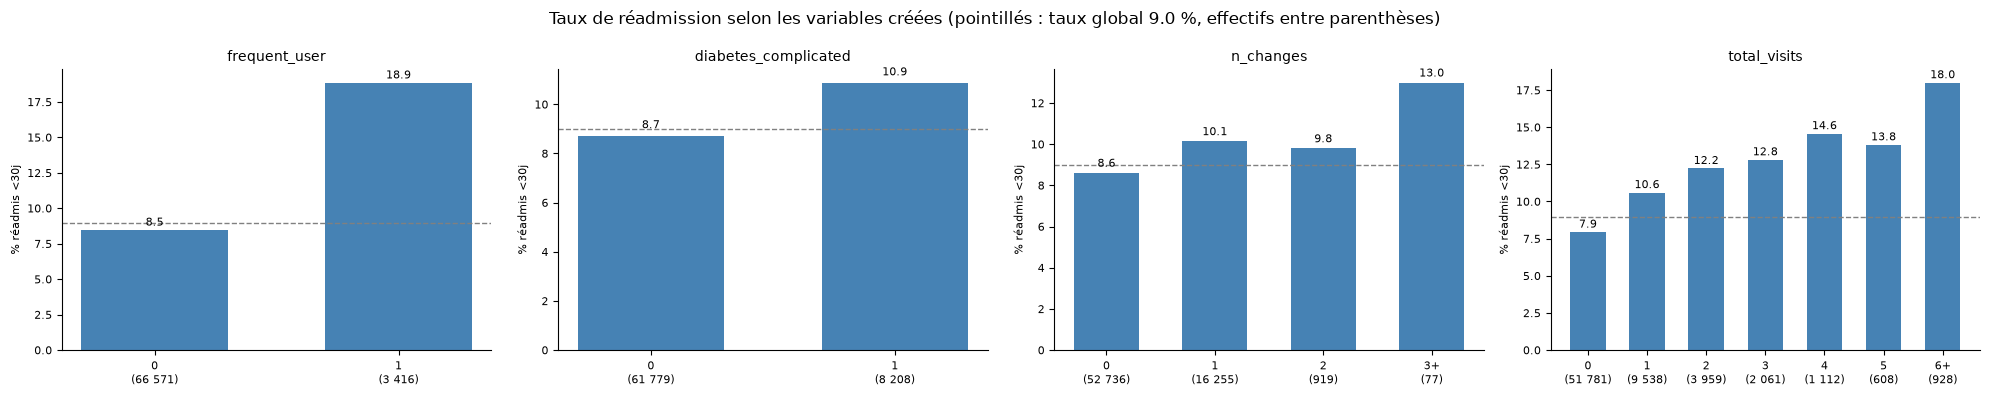

In [44]:
def tracer_serie(ax, serie, titre, plafond=None):
    """Barres : taux de réadmission pour chaque valeur de la série (plafond = regroupe 'n et plus')."""
    s = serie.clip(upper=plafond) if plafond is not None else serie
    t = df.groupby(s)['target'].agg(n='size', taux='mean')
    etiquettes = [f"{i}+" if plafond is not None and i == plafond else str(i) for i in t.index]
    etiquettes = [f"{e}\n({n:,})".replace(',', ' ') for e, n in zip(etiquettes, t['n'])]
    ax.bar(etiquettes, t['taux'] * 100, color='steelblue', width=0.6)
    ax.axhline(taux_global, color='gray', linestyle='--', linewidth=1)
    for x, v in enumerate(t['taux'] * 100):
        ax.text(x, v + 0.3, f'{v:.1f}', ha='center', fontsize=8)
    ax.set_title(titre, fontsize=10)
    ax.set_ylabel('% réadmis <30j', fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
tracer_serie(axes[0], df['frequent_user'], 'frequent_user')
tracer_serie(axes[1], df['diabetes_complicated'], 'diabetes_complicated')
tracer_serie(axes[2], df['n_changes'], 'n_changes', plafond=3)
tracer_serie(axes[3], df['total_visits'], 'total_visits', plafond=6)
fig.suptitle(f"Taux de réadmission selon les variables créées (pointillés : taux global {taux_global:.1f} %, effectifs entre parenthèses)")
plt.tight_layout()
plt.show()

**Lecture des graphiques**
- **`frequent_user`** : l'écart le plus net : 18,9 % de réadmission contre 8,5 %, pour 3 416 séjours (4,9 %).
- **`diabetes_complicated`** : 10,9 % contre 8,7 %, pour 8 208 séjours (11,7 %). L'écart est plus modeste, mais il porte sur beaucoup plus de patients.
- **`n_changes`** : 8,6 % sans changement de dose, 10,1 % avec un changement, 13,0 % à partir de 3. Cette dernière barre ne repose que sur **77 séjours** : elle n'est pas fiable. Le vrai contraste est « aucun changement » contre « au moins un ».
- **`total_visits`** : une hausse régulière de 7,9 % (aucune visite) à 18,0 % (6 visites ou plus). Le léger recul à 5 visites (13,8 %, sur 608 séjours) relève du hasard.

#### Ces variables apportent-elles plus que les colonnes d'origine ?

On compare le lien avec la cible (corrélation de Spearman, calculée sur les rangs, comme à l'étape 1) de chaque variable candidate et de la colonne dont elle est tirée. Les candidates **écartées** sont incluses : montrer ce qui ne marche pas fait partie de la justification.

In [45]:
def lien(serie):
    """Corrélation de Spearman (sur les rangs) entre une série et la cible."""
    return round(pd.concat([serie, df['target']], axis=1).rank().corr().iloc[0, 1], 3)

# Candidates écartées
diabete_250 = diag_brut.apply(lambda s: s.fillna('').str.startswith('250')).any(axis=1).astype(int)
prior_inpatient = (df['number_inpatient'] > 0).astype(int)
a1c_non_testee_et_change = ((df['A1C_tested'] == 0) & (df['change'] == 1)).astype(int)
soins_par_jour = df['num_medications'] / df['time_in_hospital']
n_medicaments = (meds_brut != 'No').sum(axis=1)
diag_9 = (df['number_diagnoses'] >= 9).astype(int)

candidates = [
    # (variable, série, {sources}, décision, raison)
    ('frequent_user', df['frequent_user'],
     {'number_inpatient': df['number_inpatient'], 'number_emergency': df['number_emergency']},
     'Retenue (lisibilité)', 'Taux doublé et simple à expliquer, mais pas plus fort que number_inpatient'),
    ('diabetes_complicated', df['diabetes_complicated'],
     {'un code 250 (diabète)': diabete_250},
     'Retenue', 'Retrouve la gravité perdue au regroupement'),
    ('n_changes', df['n_changes'],
     {'change': df['change']},
     'Retenue', 'Plus fin que change (oui / non)'),
    ('total_visits', df['total_visits'],
     {'number_inpatient': df['number_inpatient'], 'number_emergency': df['number_emergency'],
      'number_outpatient': df['number_outpatient']},
     'Retenue (clustering)', 'Résume 3 colonnes, mais plus faible que number_inpatient seule'),
    ('prior_inpatient (inpatient > 0)', prior_inpatient,
     {'number_inpatient': df['number_inpatient']},
     'Écartée', 'Copie de number_inpatient'),
    ('A1C non testée et traitement changé', a1c_non_testee_et_change,
     {'A1C_tested': df['A1C_tested']},
     'Écartée', 'Les arbres trouvent seuls les interactions'),
    ('soins par jour (médicaments / durée)', soins_par_jour,
     {'num_medications': df['num_medications']},
     'Écartée', 'Diviser par la durée détruit le signal'),
    ('nombre de médicaments du diabète', n_medicaments,
     {'diabetesMed': df['diabetesMed']},
     'Écartée', "Même information que diabetesMed, tendance irrégulière"),
    ('number_diagnoses ≥ 9', diag_9,
     {'number_diagnoses': df['number_diagnoses']},
     'Écartée', "Simple seuil sur une colonne existante (9 = limite du système ?)"),
]

lignes = []
for nom, serie, sources, decision, raison in candidates:
    meilleure = max(sources, key=lambda k: abs(lien(sources[k])))
    lignes.append({
        'Variable candidate': nom,
        'Lien avec la cible': lien(serie),
        'Meilleure source': meilleure,
        'Lien de la source': lien(sources[meilleure]),
        'Décision': decision,
        'Raison': raison,
    })
pd.DataFrame(lignes).set_index('Variable candidate')

,Lien avec la cible,Meilleure source,Lien de la source,Décision,Raison
Variable candidate,,,,,
frequent_user,0.078,number_inpatient,0.085,Retenue (lisibilité),"Taux doublé et simple à expliquer, mais pas pl..."
diabetes_complicated,0.024,un code 250 (diabète),-0.011,Retenue,Retrouve la gravité perdue au regroupement
n_changes,0.023,change,0.015,Retenue,Plus fin que change (oui / non)
total_visits,0.065,number_inpatient,0.085,Retenue (clustering),"Résume 3 colonnes, mais plus faible que number..."
prior_inpatient (inpatient > 0),0.082,number_inpatient,0.085,Écartée,Copie de number_inpatient
A1C non testée et traitement changé,0.018,A1C_tested,-0.010,Écartée,Les arbres trouvent seuls les interactions
soins par jour (médicaments / durée),-0.029,num_medications,0.042,Écartée,Diviser par la durée détruit le signal
nombre de médicaments du diabète,0.015,diabetesMed,0.028,Écartée,"Même information que diabetesMed, tendance irr..."
number_diagnoses ≥ 9,0.033,number_diagnoses,0.043,Écartée,Simple seuil sur une colonne existante (9 = li...


**Lecture du tableau**
- **Seulement 2 variables sur 4 font mieux que leur source** : `n_changes` (0,023 contre 0,015 pour `change`) et `diabetes_complicated` (0,024 contre 0,011 pour « avoir un code 250 »). Elles apportent une information nouvelle.
- **`frequent_user` (0,078) fait moins bien que `number_inpatient` (0,085)**, et `prior_inpatient` (0,082) est pratiquement identique. Transformer un comptage en indicateur oui / non **fait perdre le gradient** (1, 2, 3 hospitalisations n'ont pas le même risque). Sa valeur est la **lisibilité** (« 4,9 % des patients ont un taux de réadmission doublé »), pas un gain de performance.
- **`total_visits` (0,065) fait moins bien que `number_inpatient` (0,085)** : ajouter les consultations externes (0,016) et les urgences (0,03) **dilue** le signal des hospitalisations. Cette variable sert à résumer l'historique, pas à mieux prédire.
- **Écartées** : « soins par jour » perd tout son signal (lien de −0,029 contre 0,042 pour la colonne d'origine : diviser par la durée du séjour détruit l'information). Le nombre de médicaments du diabète et le seuil `number_diagnoses ≥ 9` ne font pas mieux que leur source. L'interaction « HbA1c non testée et traitement changé » est un peu plus liée à la cible que `A1C_tested` seule, mais très faiblement (0,018) et les arbres de décision détectent seuls ce type d'interaction.
- **Tous les liens restent faibles** (0,085 au plus) : même message que pour les variables numériques à l'étape 1. Aucune variable créée ne change cela.

#### Redondance : ces variables se recoupent-elles ?

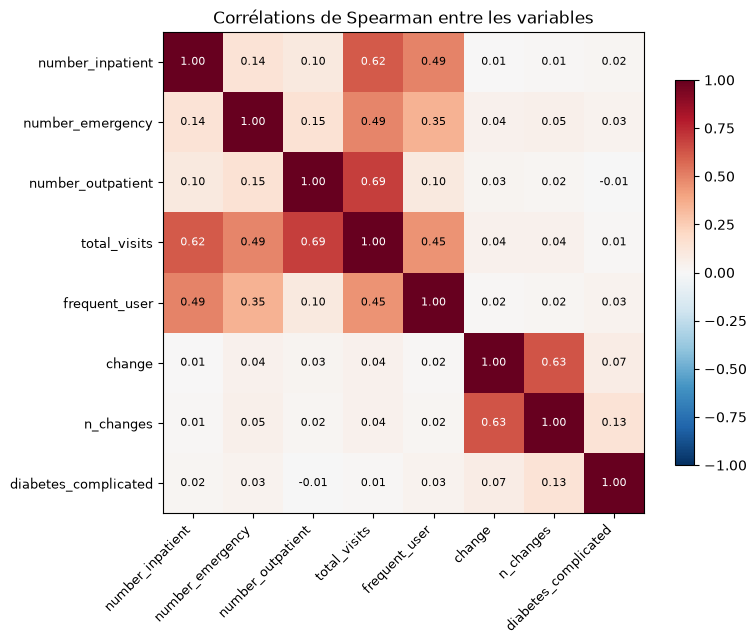

In [46]:
cols_redondance = ['number_inpatient', 'number_emergency', 'number_outpatient', 'total_visits',
                   'frequent_user', 'change', 'n_changes', 'diabetes_complicated']
corr = df[cols_redondance].rank().corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Corrélations de Spearman entre les variables')
plt.tight_layout()
plt.show()

In [47]:
# n_changes et change : le même signal ?
pd.crosstab(df['change'], df['n_changes'].clip(upper=3), margins=True)

n_changes,0,1,2,3,All
change,,,,,
0,38492,0,0,0,38492
1,14244,16255,919,77,31495
All,52736,16255,919,77,69987


**Lecture**
- **Famille « historique »** : `total_visits` est fortement corrélée à ses trois composantes (0,62 avec les hospitalisations, 0,49 avec les urgences, 0,69 avec les consultations externes), et `frequent_user` à `number_inpatient` (0,49) et `total_visits` (0,45). Ces variables contiennent la **même information** : les mettre ensemble dans un modèle (surtout une régression logistique) la compte plusieurs fois.
- **`n_changes` et `change`** : corrélées à 0,63. Le tableau croisé montre pourquoi elles ne sont pas identiques : quand `change = 0`, `n_changes` vaut toujours 0, mais **14 244 séjours** avec `change = Ch` n'ont aucune dose modifiée. `change` repère probablement aussi les ajouts, arrêts ou remplacements de médicament, alors que `n_changes` ne compte que les changements de dose.
- **`diabetes_complicated`** est presque indépendante de tout le reste (corrélations de 0,13 au plus) : c'est une information réellement nouvelle.
- **Historique et traitement** sont deux familles distinctes : leurs corrélations croisées ne dépassent pas 0,05.

#### Décision : les 4 variables sont conservées, avec des usages différents
- La transformation logarithmique de `total_visits` est ajoutée (`total_visits_log`), comme le membre 2 l'a fait pour les autres variables de visites : l'asymétrie passe de 6,7 à 1,9.
- **Segmentation (membre 4)** : `total_visits_log` peut **remplacer** les trois colonnes de visites (moins de dimensions pour K-Means). Proposition à valider avec le membre 4. `frequent_user`, `n_changes` et `diabetes_complicated` servent à **décrire les clusters** ou à les construire.
- **Classification (membre 5)** : `n_changes` et `diabetes_complicated` apportent une information nouvelle. `total_visits` et `frequent_user` recoupent les colonnes de visites : ne pas mettre `total_visits` avec ses trois composantes dans le même modèle. Garder les trois colonnes séparées est le choix le plus sûr.
- **Présentation** : `frequent_user` est la variable la plus parlante pour un public non spécialiste.

---
## 📌 Récapitulatif — Partie 2

In [48]:
texte = df.select_dtypes(include='object').columns.tolist()
print("Dimensions                  :", df.shape)
print("Valeurs manquantes          :", df.isna().sum().sum())
print("Colonnes encore textuelles  :", texte)

Dimensions                  : (69987, 47)
Valeurs manquantes          : 0
Colonnes encore textuelles  : ['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'insulin', 'diag_1_groupe', 'diag_2_groupe', 'diag_3_groupe']


C:\Users\khali\AppData\Local\Temp\ipykernel_5968\3415818679.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  texte = df.select_dtypes(include='object').columns.tolist()


| Problème | Variable(s) | Traitement | Justification |
|---|---|---|---|
| Tranches ordonnées stockées en texte | `age` | Milieu de la tranche (5 à 95) | Conserve l'ordre en une colonne ; lisible en années |
| `None` = examen non réalisé, pas un résultat | `A1Cresult`, `max_glu_serum` | Deux indicateurs 0/1 : `*_tested`, `*_high` | Sépare « examen fait » et « résultat élevé » ; les deux niveaux élevés ont des taux proches |
| Médicaments jamais ou presque jamais prescrits | 15 médicaments | Suppression (copie gardée dans `meds_brut`) | Aucune information exploitable, effectifs trop faibles |
| `Up` / `Down` trop rares | 7 médicaments | Prescrit / non prescrit (0/1) | Taux instables sur quelques dizaines de séjours |
| Niveaux de dose informatifs | `insulin` | 4 niveaux conservés | Effectifs larges, gradient de risque net |
| Variables oui / non en texte | `change`, `diabetesMed` | 0/1 | Format directement utilisable par les modèles |
| Historique résumé en une variable | `total_visits`, `total_visits_log` | Somme des 3 visites + log1p | Plus faible que `number_inpatient` seule : sert surtout à la segmentation |
| Patients très présents à l'hôpital | `frequent_user` | 1 si ≥ 2 hospitalisations ou ≥ 2 passages aux urgences | Taux de réadmission doublé (18,9 % contre 8,5 %), lisible ; pas plus fort que `number_inpatient` |
| Gravité du diabète perdue au regroupement | `diabetes_complicated` | 1 si un code ICD-9 250.1x à 250.9x | 10,9 % contre 8,7 %, information indépendante des autres variables |
| Instabilité du traitement | `n_changes` | Nombre de médicaments dont la dose a changé (sur 23) | Lien plus fort que `change` ; complète `change` |

**État à la fin de la partie 2** : 69 987 séjours, 47 colonnes, aucune valeur manquante, 11 colonnes encore textuelles.

---
### 3.10 Encodage et sauvegarde

Les modèles (K-Means, régression logistique…) ne lisent que des nombres : il reste à encoder les 11 colonnes textuelles, puis à retirer les identifiants et à sauvegarder.

**Deux fichiers** sont produits :
- **`data_etape2c_lisible.csv`** : les catégories restent en texte (`discharge_disposition_id = 'Care facility'`). C'est le fichier à utiliser pour **décrire et interpréter** (profils des clusters, graphiques de la présentation).
- **`data_etape2c_encodee.csv`** : toutes les colonnes sont numériques. C'est le fichier **de modélisation**, et le livrable « données nettoyées et préparées ».

**Encodage one-hot** : une colonne 0/1 par catégorie, car ces variables n'ont pas d'ordre (écrire Cardiology = 1 et Surgery = 2 laisserait croire que l'une vaut « plus » que l'autre). Ce choix **n'apprend rien sur les données** (il ne fait que lister les catégories) : on peut donc l'appliquer avant le découpage entraînement / test sans fuite.

Deux choix de détail :
- `gender` n'a que 2 valeurs : **une seule colonne** (`gender_Male`).
- Pour les autres, **toutes les catégories sont gardées** (pas de catégorie de référence supprimée). Cela garde chaque colonne interprétable (importance des variables, profils des clusters). Le seul inconvénient concerne les modèles linéaires non régularisés ; la régression logistique de scikit-learn est régularisée par défaut, donc non concernée.

**Identifiants** : `encounter_id` et `patient_nbr` n'ont aucun sens médical (un modèle ne pourrait que les mémoriser) : ils sont retirés des deux fichiers.

In [49]:
import re

# Fichier lisible : catégories en texte, sans identifiants
df_lisible = df.drop(columns=['encounter_id', 'patient_nbr'])
df_lisible.to_csv('data_etape2c_lisible.csv', index=False)

# Fichier encodé
df_enc = df_lisible.copy()
assert set(df_enc['gender']) == {'Female', 'Male'}
df_enc['gender_Male'] = (df_enc['gender'] == 'Male').astype(int)
df_enc = df_enc.drop(columns='gender')

a_encoder = df_enc.select_dtypes(include=['object', 'string']).columns.tolist()
print("Colonnes encodées en one-hot :", a_encoder)

df_enc = pd.get_dummies(df_enc, columns=a_encoder, dtype=int)

# Noms de colonnes sans espaces ni symboles ('Other hospital / rehab' -> 'Other_hospital_rehab')
df_enc.columns = [re.sub(r'[^0-9a-zA-Z]+', '_', c).strip('_') for c in df_enc.columns]
assert df_enc.columns.is_unique

# La cible en dernière colonne
df_enc = df_enc[[c for c in df_enc.columns if c != 'target'] + ['target']]
print("Dimensions du fichier encodé :", df_enc.shape)

Colonnes encodées en one-hot : ['race', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'insulin', 'diag_1_groupe', 'diag_2_groupe', 'diag_3_groupe']
Dimensions du fichier encodé : (69987, 107)


In [50]:
# Vérifications avant sauvegarde
assert df_enc.isna().sum().sum() == 0, "valeurs manquantes"
assert df_enc.select_dtypes(exclude='number').empty, "colonne non numérique"
for interdit in ['readmitted', 'encounter_id', 'patient_nbr']:
    assert interdit not in df_enc.columns, interdit

# Chaque séjour a exactement une catégorie par variable encodée
for col in a_encoder:
    prefixe = re.sub(r'[^0-9a-zA-Z]+', '_', col) + '_'
    assert (df_enc.filter(like=prefixe).sum(axis=1) == 1).all(), col

print("Valeurs manquantes   :", df_enc.isna().sum().sum())
print("Colonnes non numériques :", df_enc.select_dtypes(exclude='number').columns.tolist())
print("Taux de réadmission  :", f"{df_enc['target'].mean():.1%}")
print("Doublons de lignes   :", df_enc.duplicated().sum())

df_enc.to_csv('data_etape2c_encodee.csv', index=False)

Valeurs manquantes   : 0
Colonnes non numériques : []
Taux de réadmission  : 9.0%
Doublons de lignes   : 1


In [51]:
# Relecture des deux fichiers : une lecture simple (pd.read_csv) suffit désormais,
# puisque la valeur 'None' des examens n'existe plus (remplacée par les indicateurs)
lis = pd.read_csv('data_etape2c_lisible.csv')
enc = pd.read_csv('data_etape2c_encodee.csv')

print("Lisible :", lis.shape, "| manquants :", lis.isna().sum().sum(), "| 'None' restants :", (lis == 'None').sum().sum())
print("Encodé  :", enc.shape, "| manquants :", enc.isna().sum().sum())
assert lis.shape[0] == enc.shape[0] == len(df)

Lisible : (69987, 45) | manquants : 0 | 'None' restants : 0
Encodé  : (69987, 107) | manquants : 0


In [52]:
# Contenu du fichier encodé, par famille de colonnes
numeriques = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
              'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
familles = {
    'cible': ['target'],
    'numériques d\'origine (membre 2)': numeriques,
    'numériques transformées (_log)': [c for c in enc.columns if c.endswith('_log')],
    'variables créées': ['frequent_user', 'diabetes_complicated', 'n_changes', 'total_visits'],
    'âge (ordinal)': ['age'],
    'examens (indicateurs 0/1)': ['A1C_tested', 'A1C_high', 'glu_tested', 'glu_high'],
    'médicaments et traitement (0/1)': ['metformin', 'glipizide', 'glyburide', 'pioglitazone',
                                         'rosiglitazone', 'glimepiride', 'repaglinide',
                                         'change', 'diabetesMed'],
    'sexe': ['gender_Male'],
}
deja = sum(familles.values(), [])
for col in a_encoder:
    prefixe = re.sub(r'[^0-9a-zA-Z]+', '_', col) + '_'
    familles[f'one-hot : {col}'] = [c for c in enc.columns if c.startswith(prefixe) and c not in deja]
    deja += familles[f'one-hot : {col}']

assert sorted(deja) == sorted(enc.columns), "colonnes non classées"
pd.Series({k: len(v) for k, v in familles.items()}, name='colonnes').to_frame()

,colonnes
cible,1
numériques d'origine (membre 2),8
numériques transformées (_log),7
variables créées,4
âge (ordinal),1
examens (indicateurs 0/1),4
médicaments et traitement (0/1),9
sexe,1
one-hot : race,6
one-hot : admission_type_id,4


#### Remarques pour les membres 4 et 5
- Après suppression des identifiants, **1 ligne** est identique à une autre : ce sont deux patients différents aux caractéristiques identiques. Elle est conservée.
- Les 6 variables de visites / durée existent **deux fois** (valeur d'origine et `_log`) : n'utiliser que l'une des deux dans un modèle (consigne du membre 2). Les originales servent à l'interprétation.
- **Segmentation** : les 72 colonnes one-hot pèsent lourd dans les distances de K-Means. Il est préférable de segmenter sur les variables numériques et ordinales (durée, visites, `age`, médicaments, `n_changes`…) et d'utiliser les catégories du fichier **lisible** pour décrire les clusters.
- **Classification** : le fichier encodé s'utilise tel quel. La mise à l'échelle (`StandardScaler`) reste à faire **dans le pipeline**, ajustée sur l'entraînement uniquement. Utiliser `train_test_split(..., stratify=y)` pour garder 9 % de réadmis dans chaque ensemble.
- `total_visits`, `frequent_user` et les trois colonnes de visites se recoupent (voir 3.9) : éviter de tout mettre dans le même modèle.

---
## 📌 Récapitulatif final — Membre 3

| Étape | Résultat |
|---|---|
| Entrée | `data_etape2b.csv` : 69 987 séjours, 56 colonnes |
| Suppressions | `readmitted` (fuite de la cible), identifiants, 15 médicaments inutiles, codes bruts des diagnostics |
| Regroupements | codes `*_id` (20 → 6, 15 → 4, 6 → 4), `payer_code` (18 → 10), diagnostics ICD-9 (894 codes → 9 familles) |
| Encodages | `age` ordinal, examens en 2 indicateurs, médicaments en 0/1, one-hot du reste |
| Variables créées | `frequent_user`, `diabetes_complicated`, `n_changes`, `total_visits` (+ `_log`) |
| Sortie | `data_etape2c_lisible.csv` et `data_etape2c_encodee.csv` : 69 987 séjours, aucune valeur manquante |